<div dir="rtl" style="text-align: right;">
<h1>نظام مساعدة الأطباء في الكشف المبكر عن أمراض القلب</h1>
<h3>ملخص تنفيذي</h3>
<p><b>الهدف:</b> أداة تقدّر احتمال إصابة المريض بمرض القلب من معلومات وفحوصات بسيطة، لمساعدة الطبيب والممرض على ترتيب الأولويات، لا لتحل محلهما.</p>
<p><b>ما فعلناه:</b> استخدمنا بيانات 920 مريضًا من أربع مستشفيات، ونظّفناها، وفهمنا أنماطها، ثم جرّبنا خمسة نماذج تعلّم آلي وقارنّاها، واخترنا الأفضل بطريقة تحميه من الحظ.</p>
<p><b>النتيجة:</b> أفضل نموذج (SVM) اختُبر على 184 مريضًا لم يرهم من قبل:</p>
<ul>
<li>اكتشف <b>94 من 102</b> مصابًا (92%)، وفاته 8.</li>
<li>أنذر خطأً بـ 22 من 82 سليمًا.</li>
<li>أصاب في <b>84%</b> من الحالات إجمالًا.</li>
</ul>
<p><b>التوصية:</b> يصلح كنموذج أولي لمرحلة تجريبية تحت إشراف طبي، وليس للاستخدام السريري المستقل (التفاصيل والأسباب في الخلاصة الأخيرة).</p>
<h3>كيف نقرأ المقاييس؟</h3>
<ul>
<li><b>Recall (حساسية الاكتشاف):</b> من المرضى الفعليين، كم نسبة من اكتشفهم النظام؟ هو الأهم طبيًا.</li>
<li><b>Precision (صحة الإنذار):</b> من الذين أنذر بهم النظام، كم نسبة من كانوا مصابين فعلًا؟</li>
<li><b>الدقة (Accuracy):</b> نسبة القرارات الصحيحة من الإجمالي.</li>
</ul>
<h3>خريطة النوتبوك</h3>
<p>فهم البيانات وتنظيفها ← استكشافها بالرسوم ← تجهيزها ← مقارنة خمسة نماذج ← التحقق من النتائج وضبط النماذج ← تقييم النموذج النهائي وما يعتمد عليه ← نشره عبر واجهة برمجية (API) ← الخلاصة والتوصية.</p>
</div>

<div dir="rtl" style="text-align: right;">
<p><b>تجهيز أدوات التحليل والرسم.</b> خطوة تحضيرية لا أثر لها على النتائج.</p>
</div>

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

<div dir="rtl" style="text-align: right;">
<h3>تحميل بيانات المرضى</h3>
<p>كل صف في الجدول يمثل <b>مريضًا</b>، وكل عمود يمثل قياسًا أو فحصًا أو معلومة عنه. المصدر: مجموعة بيانات UCI لأمراض القلب. المسار نسبي (داخل مجلد المشروع) حتى يعمل المشروع عند أي شخص ينزّله من GitHub.</p>
</div>

In [2]:
df = pd.read_csv("../data/heart_disease_uci.csv")
df

,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
0,1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
1,2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2
2,3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
3,4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
4,5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
915,916,54,Female,VA Long Beach,asymptomatic,127.0,333.0,True,st-t abnormality,154.0,False,0.0,NaN,NaN,NaN,1
916,917,62,Male,VA Long Beach,typical angina,NaN,139.0,False,st-t abnormality,NaN,NaN,NaN,NaN,NaN,NaN,0
917,918,55,Male,VA Long Beach,asymptomatic,122.0,223.0,True,st-t abnormality,100.0,False,0.0,NaN,NaN,fixed defect,2
918,919,58,Male,VA Long Beach,asymptomatic,NaN,385.0,True,lv hypertrophy,NaN,NaN,NaN,NaN,NaN,NaN,0


<div dir="rtl" style="text-align: right;">
<h3>حجم البيانات</h3>
<p>لدينا <b>920 مريضًا</b>، ولكل مريض <b>16 معلومة</b>. هذا حجم صغير نسبيًا في عالم الذكاء الاصطناعي، وله أثر مباشر على قراءتنا للنتائج: كلما قلّت البيانات قلّت ثقتنا في الأرقام، ولذلك سنتحقق من النتائج بأكثر من طريقة قبل أن نعتمد عليها.</p>
</div>

In [3]:
df.shape

(920, 16)

<div dir="rtl" style="text-align: right;">
<h3>جودة كل معلومة ونوعها</h3>
<p>نتحقق من اكتمال كل معلومة ونوعها. <b>6 معلومات مكتملة</b> لكل المرضى (id وage وsex وdataset وcp وnum)، والبقية بها نقص. وهناك <b>8 معلومات وصفية (نصية)</b> يجب تحويلها إلى أرقام قبل أن يستطيع النموذج استخدامها.</p>
</div>

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 920 entries, 0 to 919
Data columns (total 16 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        920 non-null    int64  
 1   age       920 non-null    int64  
 2   sex       920 non-null    object 
 3   dataset   920 non-null    object 
 4   cp        920 non-null    object 
 5   trestbps  861 non-null    float64
 6   chol      890 non-null    float64
 7   fbs       830 non-null    object 
 8   restecg   918 non-null    object 
 9   thalch    865 non-null    float64
 10  exang     865 non-null    object 
 11  oldpeak   858 non-null    float64
 12  slope     611 non-null    object 
 13  ca        309 non-null    float64
 14  thal      434 non-null    object 
 15  num       920 non-null    int64  
dtypes: float64(5), int64(3), object(8)
memory usage: 115.1+ KB


<div dir="rtl" style="text-align: right;">
<h3>ملخص إحصائي للقياسات الرقمية</h3>
<p>نبحث هنا عن قيم غير منطقية. <b>ملاحظة مهمة:</b> أقل قيمة للكوليسترول (chol) وأقل قيمة لضغط الدم (trestbps) هي <b>صفر</b>، وهذا مستحيل طبيًا، فهو على الأرجح «غير مقاس» كُتب صفرًا. لو تركناه لضلل النموذج. سنعالجه بعد قليل.</p>
</div>

In [5]:
df.describe()

,id,age,trestbps,chol,thalch,oldpeak,ca,num
count,920.000000,920.000000,861.000000,890.000000,865.000000,858.000000,309.000000,920.000000
mean,460.500000,53.510870,132.132404,199.130337,137.545665,0.878788,0.676375,0.995652
std,265.725422,9.424685,19.066070,110.780810,25.926276,1.091226,0.935653,1.142693
min,1.000000,28.000000,0.000000,0.000000,60.000000,-2.600000,0.000000,0.000000
25%,230.750000,47.000000,120.000000,175.000000,120.000000,0.000000,0.000000,0.000000
50%,460.500000,54.000000,130.000000,223.000000,140.000000,0.500000,0.000000,1.000000
75%,690.250000,60.000000,140.000000,268.000000,157.000000,1.500000,1.000000,2.000000
max,920.000000,77.000000,200.000000,603.000000,202.000000,6.200000,3.000000,4.000000


<div dir="rtl" style="text-align: right;">
<h3>أين النقص في البيانات؟</h3>
<p>نعدّ الخانات الفارغة في كل معلومة. هذه الخطوة تحدد ما إذا كانت المعلومة صالحة للاعتماد عليها أم لا. أكثر المعلومات نقصًا: <b>ca</b> (611 مريضًا بلا قيمة)، ثم <b>thal</b> (486)، ثم <b>slope</b> (309). أما العمر والجنس ونوع ألم الصدر فمكتملة لكل المرضى.</p>
</div>

In [6]:
df.isnull().sum()

id            0
age           0
sex           0
dataset       0
cp            0
trestbps     59
chol         30
fbs          90
restecg       2
thalch       55
exang        55
oldpeak      62
slope       309
ca          611
thal        486
num           0
dtype: int64

<div dir="rtl" style="text-align: right;">
<h3>هل هناك مريض مسجل مرتين؟</h3>
<p>التكرار يضخم الدقة بشكل وهمي، لأن النموذج قد يُختبر على حالة سبق أن تعلمها. النتيجة 0، لكن يجب الانتباه إلى أن وجود العمود id (فريد لكل صف) يجعل هذا الفحص لا يكشف أي تكرار حقيقي. بعد حذف id يظهر <b>صفّان مكرران فقط</b> (أقل من 0.3% من البيانات)، وتأثيرهما على النتائج ضئيل، ويمكن حذفهما في نسخة لاحقة.</p>
</div>

In [7]:
 df.duplicated().sum()

0

<div dir="rtl" style="text-align: right;">
<h3>ماذا نريد أن نتنبأ به؟</h3>
<p>العمود <b>num</b> يصف حالة القلب بدرجات من 0 (سليم) إلى 4 (الأشد). العدد: <b>411 سليمًا</b> و<b>509 مرضى</b> موزعين على الدرجات 1 إلى 4 (265 و109 و107 و28). لاحظ أن الدرجة 4 فيها 28 مريضًا فقط.</p>
</div>

In [8]:
df['num'].value_counts().sort_index()

num
0    411
1    265
2    109
3    107
4     28
Name: count, dtype: int64

<div dir="rtl" style="text-align: right;">
<h3>قرار: نبسّط السؤال إلى «مصاب أم سليم؟»</h3>
<p>بدل أن نتنبأ بدرجة المرض، نسأل سؤالًا واحدًا: هل المريض مصاب؟ (1 = مصاب، 0 = سليم).</p>
<ul>
<li><b>السبب:</b> هدف الأداة هو الفرز المبدئي لمساعدة الطبيب، وعدد الحالات في بعض الدرجات (28 حالة في الدرجة الأخيرة) لا يكفي لتعلم التمييز بينها بثقة.</li>
<li><b>الأثر:</b> يصبح التوزيع متوازنًا تقريبًا: 509 مصابين (55%) مقابل 411 سليمًا (45%)، فلا نحتاج إلى معالجات خاصة لموازنة البيانات.</li>
</ul>
</div>

In [9]:
df['target'] = (df['num'] > 0).astype(int)

<div dir="rtl" style="text-align: right;">
<h3>قرار: نحذف ثلاث معلومات من مدخلات النموذج</h3>
<ul>
<li><b>id:</b> رقم تسلسلي للمريض، ليس له معنى طبي.</li>
<li><b>dataset:</b> اسم المستشفى الذي جمع البيانات. نريد أن يقرر النموذج من حالة المريض لا من اسم المستشفى، والطبيب الذي سيستخدم النظام لا يملك هذه المعلومة أصلًا.</li>
<li><b>num:</b> هي «الإجابة» نفسها بعد أن حولناها إلى target. لو تركناها بين المدخلات لحصلنا على دقة شبه كاملة مخادعة، ثم ينهار النموذج عند أول مريض حقيقي لأن الإجابة لن تكون معروفة له. (يسمى هذا تسريب البيانات.)</li>
</ul>
</div>

In [10]:
df = df.drop(columns = ['id', 'dataset', 'num'])

<div dir="rtl" style="text-align: right;">
<h3>قرار مبني على النسب: ما الذي نحذفه؟</h3>
<p>نرتب المعلومات حسب نسبة النقص. القاعدة التي نتبعها: <b>لا نعوّض معلومة نصفها أو أكثر فارغ</b>، لأننا حينها نخترع أغلب قيمها بدل أن نقيسها. هنا <b>ca</b> ناقصة بنسبة 66% و<b>thal</b> بنسبة 53%.</p>
</div>

In [11]:
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(1)
pd.DataFrame({'missing': missing, 'pct %': missing_pct}).sort_values('pct %', ascending=False)


,missing,pct %
ca,611,66.4
thal,486,52.8
slope,309,33.6
fbs,90,9.8
oldpeak,62,6.7
trestbps,59,6.4
thalch,55,6.0
exang,55,6.0
chol,30,3.3
restecg,2,0.2


<div dir="rtl" style="text-align: right;">
<p><b>حذف ca:</b> ثلثا قيمها مفقودة. تعويضها يعني تخمين قيمة 611 مريضًا من أصل 920، ولا يصح أن يُبنى قرار طبي على تخمين.</p>
</div>

In [12]:
df = df.drop(columns=['ca'])

<div dir="rtl" style="text-align: right;">
<p><b>حذف thal:</b> أكثر من نصف قيمها مفقودة (53%) فنحذفها للسبب نفسه. <b>الثمن:</b> نخسر معلومة قد تكون مفيدة طبيًا (فحص الثاليوم لتروية القلب)، لكن الاحتفاظ بها كان سيجعل النموذج يتعلم من تخمين أكثر مما يتعلم من مرضى حقيقيين.</p>
</div>

In [13]:
df = df.drop(columns=['thal'])

<div dir="rtl" style="text-align: right;">
<h3>تنظيف: صفر الكوليسترول والضغط ليس قياسًا حقيقيًا</h3>
<p>وجود كوليسترول أو ضغط دم يساوي صفرًا مستحيل طبيًا؛ الأرجح أن نظام التسجيل كتب صفرًا بدل «غير مقاس». نحوّل هذه الأصفار إلى «قيمة غير معروفة» حتى لا يتعلم النموذج منها.</p>
<p><b>الأثر:</b> يتضح أن النقص الحقيقي في الكوليسترول هو <b>202 مريضًا (22%)</b> وليس 30 كما كان يبدو. أي أن البيانات أقل جودة مما تُظهره الأرقام الأولى، وهذه معلومة مهمة لمن يقيّم موثوقية النظام.</p>
</div>

In [14]:
df['chol'] = df['chol'].replace(0, np.nan)
df['trestbps'] = df['trestbps'].replace(0, np.nan)


<div dir="rtl" style="text-align: right;">
<h2>هل في البيانات أنماط منطقية طبيًا؟</h2>
<p>قبل بناء النموذج نفحص البيانات بالرسوم. إذا وجدنا أنماطًا تتفق مع المعرفة الطبية فهذا يعطينا ثقة بأن النموذج سيتعلم شيئًا حقيقيًا، وإن لم نجد فهذا إنذار مبكر.</p>
<p><b>الرسم الأول: توزيع الحالات.</b> 411 سليمًا مقابل 509 مصابين: عدد الفئتين متقارب، فالنموذج لن «يتحيز» لفئة على حساب الأخرى.</p>
</div>

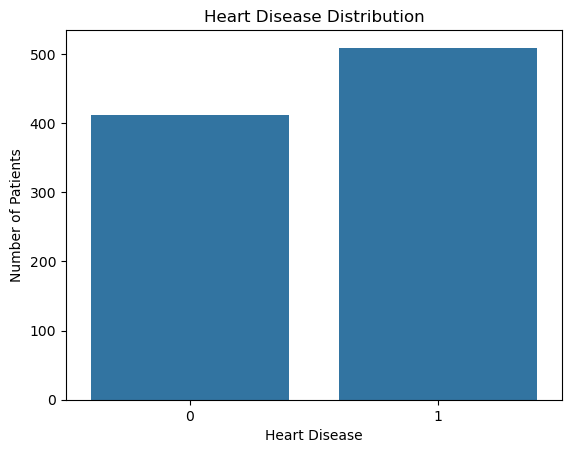

In [15]:
sns.countplot(data=df, x='target')

plt.title('Heart Disease Distribution')
plt.xlabel('Heart Disease')
plt.ylabel('Number of Patients')

plt.show()

<div dir="rtl" style="text-align: right;">
<p><b>توزيع الأعمار:</b> المرضى بين 28 و77 سنة، ومتوسط العمر 53.5. نحو نصف المرضى (51%) بين 50 و62 سنة. <b>الأثر:</b> النموذج تعلّم أساسًا من منتصف العمر وكبار السن، فأداؤه على الشباب أقل موثوقية.</p>
</div>

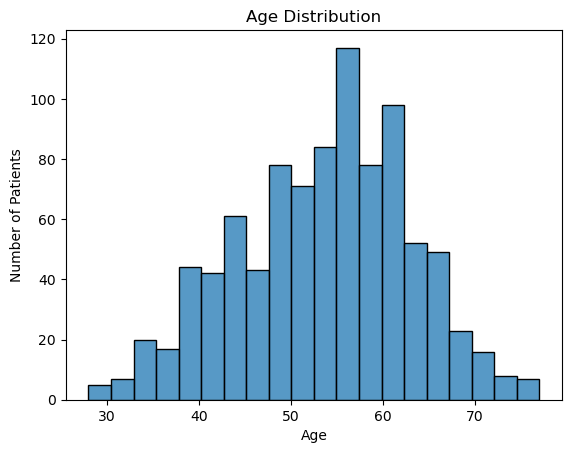

In [16]:
sns.histplot(data=df, x='age', bins=20)

plt.title('Age Distribution')
plt.xlabel('Age')
plt.ylabel('Number of Patients')

plt.show()

<div dir="rtl" style="text-align: right;">
<p><b>هل يفرق العمر بين المصاب والسليم؟</b> نعم جزئيًا: وسيط عمر المصابين 57 سنة مقابل 51 للأصحاء. لكن الصندوقين متداخلان كثيرًا، أي أن العمر وحده لا يكفي للحكم على مريض. والنقاط الشاذة تمثل مصابين صغار السن، وهي حالات حقيقية لا نحذفها.</p>
</div>

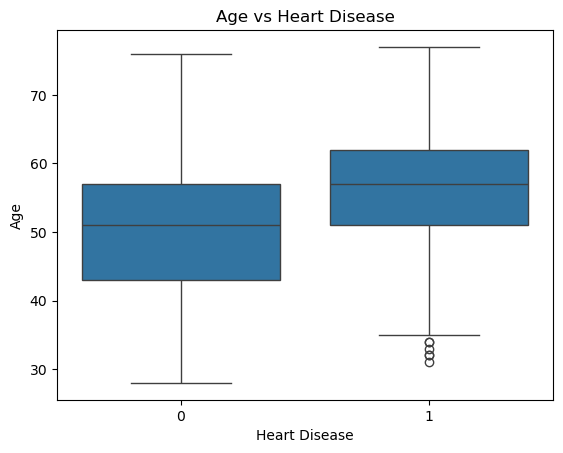

In [17]:
sns.boxplot(data=df, x='target', y='age')

plt.title('Age vs Heart Disease')
plt.xlabel('Heart Disease')
plt.ylabel('Age')

plt.show()

<div dir="rtl" style="text-align: right;">
<p><b>أقوى نمط في البيانات: نوع ألم الصدر.</b></p>
<ul>
<li>496 مريضًا بلا ألم صدر نموذجي (asymptomatic): <b>79% منهم مصابون</b>. المعنى العملي: غياب الألم لا يعني السلامة.</li>
<li>174 مريضًا بألم غير نموذجي (atypical angina): 14% فقط مصابون.</li>
<li>فئة typical angina عددها 46 فقط، فلا نبني عليها استنتاجًا.</li>
</ul>
<p>هذا يرجّح أن نوع الألم سيكون من أهم المعلومات التي يعتمد عليها النموذج.</p>
</div>

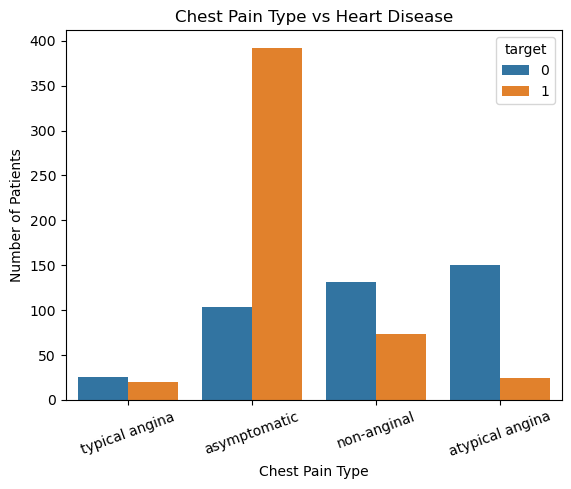

In [18]:
sns.countplot(data=df, x='cp', hue='target')

plt.title('Chest Pain Type vs Heart Disease')
plt.xlabel('Chest Pain Type')
plt.ylabel('Number of Patients')

plt.xticks(rotation=20)

plt.show()

<div dir="rtl" style="text-align: right;">
<p><b>أي القياسات الرقمية أقرب إلى تفسير المرض؟</b> ننظر إلى صف <b>target</b> فقط (القيم القريبة من 1 أو −1 علاقة قوية، والقريبة من 0 ضعيفة):</p>
<ul>
<li><b>oldpeak (+0.39):</b> كلما زاد انخفاض مقطع ST في رسم القلب أثناء المجهود زاد احتمال المرض.</li>
<li><b>thalch (−0.39):</b> كلما قل أقصى نبض يبلغه المريض أثناء المجهود زاد احتمال المرض.</li>
<li><b>العمر (+0.28):</b> علاقة متوسطة.</li>
<li><b>الكوليسترول والضغط (0.12):</b> علاقة ضعيفة في هذه البيانات رغم شهرتهما.</li>
</ul>
<p>تنبيه: الارتباط لا يعني السببية، ولا يشمل المعلومات النصية مثل نوع الألم.</p>
</div>

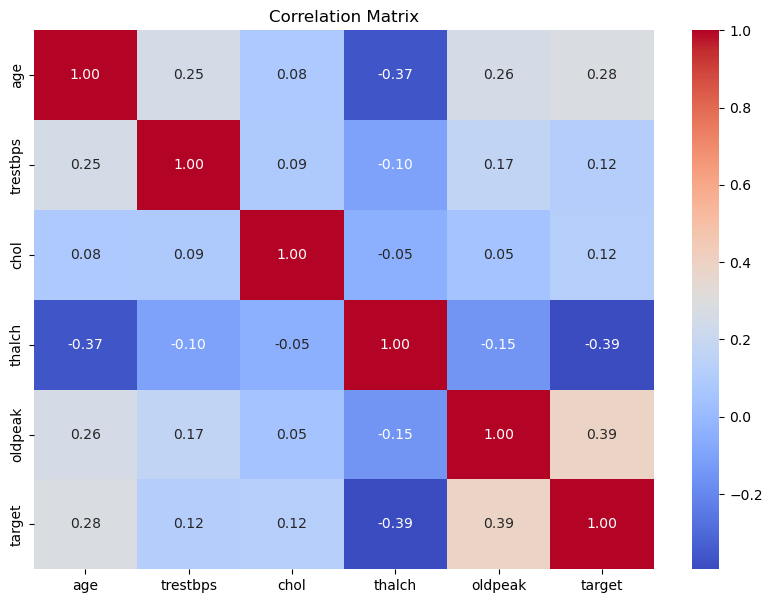

In [19]:
numeric_df = df[
    ['age', 'trestbps', 'chol', 'thalch', 'oldpeak', 'target']
]

corr = numeric_df.corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Matrix')

plt.show()

<div dir="rtl" style="text-align: right;">
<p><b>حصيلة النقص بعد التنظيف:</b> ما زال النقص موجودًا في slope (309)، وchol (202)، وfbs (90)، وoldpeak (62)، وtrestbps (60)، وthalch وexang (55 لكل منهما)، وrestecg (2). لن نحذف هذه المعلومات لأن نسب نقصها محتملة، بل سنعوض الناقص بشكل منضبط داخل خط المعالجة <b>بعد تقسيم المرضى</b>، حتى لا يتسرب شيء من بيانات الاختبار.</p>
</div>

In [20]:
df.isnull().sum()

age           0
sex           0
cp            0
trestbps     60
chol        202
fbs          90
restecg       2
thalch       55
exang        55
oldpeak      62
slope       309
target        0
dtype: int64

<div dir="rtl" style="text-align: right;">
<p><b>ملاحظة فنية لا تؤثر على النتائج:</b> هذه قائمة مرجعية بأسماء الأعمدة، لكنها لا تُستخدم في أي خطوة لاحقة، وينقصها العمود cp (النموذج يستخدم 11 عمودًا منها cp). يمكن حذفها أو تحديثها دون أثر على المشروع.</p>
</div>

In [21]:
features = [
    'age',
    'sex',
    'trestbps',
    'chol',
    'fbs',
    'restecg',
    'thalch',
    'exang',
    'oldpeak',
    'slope'
]

<div dir="rtl" style="text-align: right;">
<h3>نفصل «ما يعرفه الطبيب» عن «ما نريد توقعه»</h3>
<p>نضع في جهة 11 معلومة عن المريض (العمر، الجنس، الفحوصات...)، وفي جهة أخرى الإجابة المطلوبة (مصاب أو سليم). الغرض ألا يرى النموذج الإجابة أثناء التعلم.</p>
</div>

In [22]:
X = df.drop(columns=['target'])
y = df['target']

<div dir="rtl" style="text-align: right;">
<p><b>فحص سلامة:</b> عدد المرضى متطابق (920) في الجهتين، ولكل مريض 11 معلومة. نتأكد قبل المتابعة لأن أي اختلاف هنا يعني أن بيانات المرضى اختلطت.</p>
</div>

In [23]:
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (920, 11)
y shape: (920,)


<div dir="rtl" style="text-align: right;">
<h3>قرار: نخفي 20% من المرضى لنختبر عليهم في النهاية</h3>
<p>نقسم المرضى إلى: <b>736 مريضًا</b> يتعلم منهم النموذج، و<b>184 مريضًا</b> نحجبهم تمامًا ونستخدمهم كاختبار نهائي، كأننا نجرّب النظام على مرضى جدد. هذا ما يفرّق بين نموذج «يحفظ» ما رآه ونموذج «يفهم» ويصلح للمرضى الجدد.</p>
<p>نحافظ على نسبة المصابين نفسها في الجزأين، ونثبّت التقسيم حتى تتكرر النتائج في كل تشغيل. <b>قاعدة نلتزم بها:</b> لا نختار النموذج النهائي بالنظر إلى هؤلاء الـ 184 وحدهم.</p>
</div>

In [24]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

<div dir="rtl" style="text-align: right;">
<h3>نعامل كل نوع من المعلومات بما يناسبه</h3>
<p>نفرّق بين قياسات رقمية (العمر، الضغط، الكوليسترول، أقصى نبض، oldpeak) ومعلومات وصفية (الجنس، نوع الألم، سكر الدم...). كل نوع يحتاج معاملة مختلفة. الهدف: <b>ألا نتجاهل أي معلومة متاحة عن المريض</b>، وأن نجهزها بالطريقة الصحيحة.</p>
</div>

In [25]:
numeric_features = [
    'age',
    'trestbps',
    'chol',
    'thalch',
    'oldpeak'
]

categorical_features = [
    'sex',
    'cp',
    'fbs',
    'restecg',
    'exang',
    'slope'
]

<div dir="rtl" style="text-align: right;">
<p>خطوة تحضيرية: نستدعي أدوات التجهيز. لا قرارات هنا؛ المهم ما نفعله بها في الخلايا التالية.</p>
</div>

In [26]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

<div dir="rtl" style="text-align: right;">
<h3>القياسات الرقمية: تعويض عادل وتوحيد المقياس</h3>
<ul>
<li><b>الناقص:</b> نعوضه بالقيمة الوسطى بين المرضى (الوسيط). اختيار محافظ لا يتأثر بالحالات المتطرفة.</li>
<li><b>توحيد المقياس:</b> الكوليسترول بالمئات وoldpeak بالآحاد؛ لو تركناهما كما هما لطغى الرقم الكبير على الصغير. التوحيد يعطي كل معلومة فرصة عادلة.</li>
</ul>
</div>

In [27]:
numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

<div dir="rtl" style="text-align: right;">
<h3>المعلومات الوصفية: تعويض بالأكثر شيوعًا ثم تحويل لأرقام</h3>
<ul>
<li><b>الناقص:</b> نعوضه بالإجابة الأكثر تكرارًا بين المرضى. <b>افتراض يجب الانتباه إليه:</b> نعتبر أن المريض الذي لم تُسجَّل معلومته «عادي»، وهذا افتراض متفائل قد لا يصح دائمًا.</li>
<li><b>التحويل لأرقام:</b> النموذج لا يفهم النصوص، فنحول كل إجابة إلى خانة نعم/لا. وإن ظهرت إجابة جديدة وقت التشغيل لا يتعطل النظام.</li>
</ul>
</div>

In [28]:
categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

<div dir="rtl" style="text-align: right;">
<h3>خطة واحدة تُطبَّق على أي مريض جديد</h3>
<p>نجمع المعالجتين (الرقمية والوصفية) في خطة واحدة. <b>الفائدة العملية:</b> عندما يعمل النظام فعليًا، تُعالَج بيانات المريض الجديد بنفس الطريقة التي تعلّم بها النموذج، فلا يختلف الأداء بين التجربة والتشغيل.</p>
</div>

In [29]:
preprocessor = ColumnTransformer([
    ('num', numeric_pipeline, numeric_features),
    ('cat', categorical_pipeline, categorical_features)
])

<div dir="rtl" style="text-align: right;">
<h3>نحسب قواعد التجهيز من مرضى التدريب فقط</h3>
<p>القيم الوسطى والمقاييس نحسبها من مرضى التدريب، ثم نطبقها على مرضى الاختبار دون أن نتعلم منهم شيئًا. لو حسبناها من الجميع لتسربت معلومات الاختبار إلى النموذج، وصارت النتيجة أجمل من الواقع. <b>الأثر:</b> نتيجة الاختبار تعكس ما سيحدث مع مريض جديد فعلًا.</p>
</div>

In [30]:
X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

<div dir="rtl" style="text-align: right;">
<h3>النموذج الأول: Logistic Regression (خط الأساس)</h3>
<p>أبسط النماذج وأسهلها شرحًا للطبيب، إذ يعطي وزنًا لكل معلومة ثم يحسب احتمال الإصابة. نبدأ به كمقياس أساسي: <b>أي نموذج أعقد يجب أن يتفوق عليه ليبرر تعقيده.</b></p>
</div>

In [31]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

model.fit(X_train_processed, y_train)

LogisticRegression(max_iter=1000, random_state=42)

<div dir="rtl" style="text-align: right;">
<p>نطلب من النموذج توقع حالة 184 مريضًا لم يرهم من قبل، ثم نقارن توقعاته بالحقيقة التي نعرفها نحن.</p>
</div>

In [32]:
y_pred = model.predict(X_test_processed)

<div dir="rtl" style="text-align: right;">
<p><b>هكذا يرى النموذج المريض:</b> أرقام فقط. لا حاجة لفهم تفاصيل هذه الخلية؛ هي تُظهر فقط أن المعلومات الوصفية تحولت إلى أرقام وأن القياسات وُحّدت.</p>
</div>

In [33]:
X_train_processed

array([[-0.06314684,  1.56027016, -0.11087982, ...,  0.        ,
         1.        ,  0.        ],
       [ 2.1805258 , -0.11641087, -0.11087982, ...,  0.        ,
         1.        ,  0.        ],
       [-0.06314684, -0.45174708, -0.03635238, ...,  0.        ,
         1.        ,  0.        ],
       ...,
       [ 1.32579336,  1.00137648, -0.11087982, ...,  0.        ,
         1.        ,  0.        ],
       [ 0.47106093,  1.00137648,  0.70892201, ...,  0.        ,
         0.        ,  1.        ],
       [-1.98629482, -0.67530455,  1.1747185 , ...,  0.        ,
         1.        ,  0.        ]])

<div dir="rtl" style="text-align: right;">
<p><b>الدقة 79.3%:</b> من كل 100 مريض جديد يصيب النموذج في نحو 79. رقم مفيد لكنه مضلل وحده، لأن الخطأ لا يتساوى: أن نقول لمريض إنه سليم وهو مصاب أخطر بكثير من أن ننذر سليمًا. لذلك ننظر في المقاييس التالية.</p>
</div>

In [34]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

Accuracy: 0.7934782608695652


<div dir="rtl" style="text-align: right;">
<p><b>نفصل الأداء إلى مقياسين يهمان صاحب القرار:</b></p>
<ul>
<li><b>Recall (حساسية الاكتشاف):</b> من المرضى الفعليين، كم نسبة من اكتشفناهم؟ هنا <b>84%</b>. وهو المقياس الأهم طبيًا لأن تفويت مريض أخطر من إنذار كاذب.</li>
<li><b>Precision (صحة الإنذار):</b> من الذين أنذرنا بإصابتهم، كم كانوا مصابين فعلًا؟ هنا <b>80%</b>.</li>
</ul>
</div>

In [35]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.79      0.73      0.76        82
           1       0.80      0.84      0.82       102

    accuracy                           0.79       184
   macro avg       0.79      0.79      0.79       184
weighted avg       0.79      0.79      0.79       184



<div dir="rtl" style="text-align: right;">
<p><b>نترجم النسب إلى عدد مرضى</b> (من 184 مريضًا في الاختبار):</p>
<ul>
<li>اكتشف <b>86</b> مريضًا من أصل 102 مصاب، وفاته <b>16</b> (هذا هو الخطأ الأخطر).</li>
<li>أنذر <b>22</b> سليمًا من أصل 82 خطأً (إنذار كاذب: فحوصات إضافية وقلق للمريض، لكنه أقل خطورة).</li>
</ul>
</div>

In [36]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print(cm)

[[60 22]
 [16 86]]


<div dir="rtl" style="text-align: right;">
<p>الأرقام نفسها في خريطة لونية: القطر (60 و86) هو القرارات الصحيحة، والمربعان الآخران هما الأخطاء.</p>
</div>

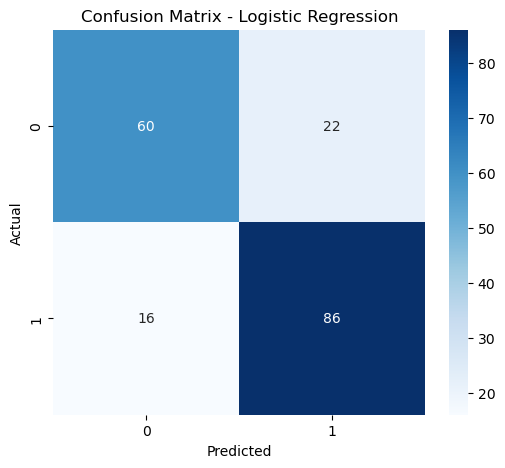

In [37]:
plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title('Confusion Matrix - Logistic Regression')
plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.show()

<div dir="rtl" style="text-align: right;">
<h3>النموذج الثاني: شجرة القرار (Decision Tree)</h3>
<p>يتخذ القرار بتسلسل أسئلة بسيطة (مثل: هل العمر أكبر من 55؟) ويمكن تتبع منطقه بسهولة. <b>عيبه:</b> يميل إلى «حفظ» بيانات التدريب إن لم نقيّده، فيبدو جيدًا أثناء التعلم ويضعف مع المرضى الجدد.</p>
</div>

In [38]:
from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(
    random_state=42
)

dt_model.fit(X_train_processed, y_train)

dt_pred = dt_model.predict(X_test_processed)

<div dir="rtl" style="text-align: right;">
<p><b>النتيجة:</b> دقة 76.6% (الأقل بين النماذج حتى الآن). اكتشف 83 مريضًا من 102 وفاته 19.</p>
</div>

In [39]:
from sklearn.metrics import accuracy_score, classification_report

dt_accuracy = accuracy_score(y_test, dt_pred)

print("Decision Tree Accuracy:", dt_accuracy)
print(classification_report(y_test, dt_pred))

Decision Tree Accuracy: 0.7663043478260869
              precision    recall  f1-score   support

           0       0.75      0.71      0.73        82
           1       0.78      0.81      0.79       102

    accuracy                           0.77       184
   macro avg       0.76      0.76      0.76       184
weighted avg       0.77      0.77      0.77       184



<div dir="rtl" style="text-align: right;">
<h3>النموذج الثالث: Random Forest (الغابة العشوائية)</h3>
<p>بدل شجرة واحدة، يستشير <b>200 شجرة</b> ويأخذ برأي الأغلبية. الفكرة أن رأي الجماعة أثبت من رأي فرد. غالبًا يكون أدق من الشجرة الواحدة، ولكنه أصعب في الشرح لطبيب.</p>
</div>

In [40]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

rf_model.fit(X_train_processed, y_train)

rf_pred = rf_model.predict(X_test_processed)

<div dir="rtl" style="text-align: right;">
<p><b>النتيجة:</b> دقة 81.5%. اكتشف 90 مريضًا من 102 وفاته 12، وهو تحسن واضح عن الشجرة الواحدة (83 اكتشافًا).</p>
</div>

In [41]:
rf_accuracy = accuracy_score(y_test, rf_pred)

print("Random Forest Accuracy:", rf_accuracy)
print(classification_report(y_test, rf_pred))

Random Forest Accuracy: 0.8152173913043478
              precision    recall  f1-score   support

           0       0.83      0.73      0.78        82
           1       0.80      0.88      0.84       102

    accuracy                           0.82       184
   macro avg       0.82      0.81      0.81       184
weighted avg       0.82      0.82      0.81       184



<div dir="rtl" style="text-align: right;">
<h3>النموذج الرابع: KNN (أقرب الجيران)</h3>
<p>يقارن المريض الجديد بأقرب 5 مرضى مشابهين له في البيانات ويأخذ برأي الأغلبية، أي منطق «قِس على حالات مشابهة». يعتمد على المسافات، لذلك كان توحيد المقياس ضروريًا له.</p>
<p>ملاحظة: التحذير الذي يظهر أسفل الخلية خاص بنظام Windows ولا يؤثر على النتائج.</p>
</div>

In [42]:
from sklearn.neighbors import KNeighborsClassifier

knn_model = KNeighborsClassifier(
    n_neighbors=5
)

knn_model.fit(X_train_processed, y_train)

knn_pred = knn_model.predict(X_test_processed)

C:\Users\User\anaconda3\lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\User\anaconda3\lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
  File "C:\Users\User\anaconda3\lib\subprocess.py", line 505, in run
    with Popen(*popenargs, **kwargs) as process:
  File "C:\Users\User\anaconda3\lib\subprocess.py", line 951, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Users\User\anaconda3\lib\subprocess.py", line 1436, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,


<div dir="rtl" style="text-align: right;">
<p><b>النتيجة:</b> دقة 78.8%. اكتشف 87 مريضًا من 102 وفاته 15، وهو قريب من النموذج الأساسي.</p>
</div>

In [43]:
knn_accuracy = accuracy_score(y_test, knn_pred)

print("KNN Accuracy:", knn_accuracy)
print(classification_report(y_test, knn_pred))

KNN Accuracy: 0.7880434782608695
              precision    recall  f1-score   support

           0       0.79      0.71      0.75        82
           1       0.78      0.85      0.82       102

    accuracy                           0.79       184
   macro avg       0.79      0.78      0.78       184
weighted avg       0.79      0.79      0.79       184



<div dir="rtl" style="text-align: right;">
<h3>النموذج الخامس: SVM</h3>
<p>يبحث عن أفضل حد فاصل بين المصابين والأصحاء، ويستطيع رسم حد معقد غير مستقيم. نطلب منه أيضًا <b>نسبة احتمال الإصابة</b> وليس مجرد نعم أو لا، لأن النظام سيعرض هذه النسبة للطبيب وسيحتاجها للتنبيه المبكر عبر الـ API.</p>
</div>

In [44]:
from sklearn.svm import SVC

svm_model = SVC(
    kernel='rbf',
    probability=True,
    random_state=42
)

svm_model.fit(X_train_processed, y_train)

svm_pred = svm_model.predict(X_test_processed)

<div dir="rtl" style="text-align: right;">
<p><b>النتيجة (الأفضل حتى الآن):</b> دقة 83.7%. اكتشف <b>94</b> مريضًا من 102 (92%) وفاته <b>8 فقط</b>.</p>
</div>

In [45]:
svm_accuracy = accuracy_score(y_test, svm_pred)

print("SVM Accuracy:", svm_accuracy)
print(classification_report(y_test, svm_pred))

SVM Accuracy: 0.8369565217391305
              precision    recall  f1-score   support

           0       0.88      0.73      0.80        82
           1       0.81      0.92      0.86       102

    accuracy                           0.84       184
   macro avg       0.85      0.83      0.83       184
weighted avg       0.84      0.84      0.83       184



<div dir="rtl" style="text-align: right;">
<p>نجمع نتائج النماذج الخمسة في مكان واحد لنقارنها بنفس المعيار وعلى نفس المرضى. خطوة تجميع فقط، والنتيجة في الخلية التالية.</p>
</div>

In [46]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

results = []

models_predictions = {
    'Logistic Regression': y_pred,
    'Decision Tree': dt_pred,
    'Random Forest': rf_pred,
    'KNN': knn_pred,
    'SVM': svm_pred
}

for name, predictions in models_predictions.items():

    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, predictions),
        'Precision': precision_score(y_test, predictions),
        'Recall': recall_score(y_test, predictions),
        'F1 Score': f1_score(y_test, predictions)
    })

<div dir="rtl" style="text-align: right;">
<h3>المقارنة بين النماذج الخمسة (على 184 مريضًا)</h3>
<p>الخلية التالية تعرض النتائج مرتبة بمقياس F1 الذي يوازن بين الاكتشاف والإنذار الكاذب. وهذه ترجمتها إلى عدد مرضى، وهي الأقرب لعين صاحب القرار:</p>
<table>
<tr><th>النموذج</th><th>الدقة</th><th>مصابون اكتشفهم (من 102)</th><th>مصابون فاتوه</th><th>إنذارات كاذبة (من 82 سليمًا)</th></tr>
<tr><td>SVM</td><td>83.7%</td><td>94</td><td><b>8</b></td><td>22</td></tr>
<tr><td>Random Forest</td><td>81.5%</td><td>90</td><td>12</td><td>22</td></tr>
<tr><td>Logistic Regression</td><td>79.3%</td><td>86</td><td>16</td><td>22</td></tr>
<tr><td>KNN</td><td>78.8%</td><td>87</td><td>15</td><td>24</td></tr>
<tr><td>Decision Tree</td><td>76.6%</td><td>83</td><td>19</td><td>24</td></tr>
</table>
<p><b>القراءة:</b> الإنذارات الكاذبة متقاربة بين النماذج (22 إلى 24)، والفارق الحقيقي في عدد المصابين الذين يفوتهم النموذج (من 8 إلى 19). لكن الاختبار 184 مريضًا فقط، فالفروق الصغيرة قد تكون صدفة، ولهذا نتحقق بطريقة أصلب في الخطوات التالية.</p>
</div>

In [47]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by='F1 Score',
    ascending=False
)

results_df

,Model,Accuracy,Precision,Recall,F1 Score
4,SVM,0.836957,0.810345,0.921569,0.862385
2,Random Forest,0.815217,0.803571,0.882353,0.841121
0,Logistic Regression,0.793478,0.796296,0.843137,0.819048
3,KNN,0.788043,0.783784,0.852941,0.816901
1,Decision Tree,0.766304,0.775701,0.813725,0.794258


<div dir="rtl" style="text-align: right;">
<h3>المقارنة بالرسم</h3>
<p>الصورة نفسها بالرسم لتظهر الفروق بنظرة واحدة. ننتبه خاصة إلى <b>Recall</b> لأن أخطر خطأ في التشخيص أن نطمئن مريضًا مصابًا.</p>
</div>

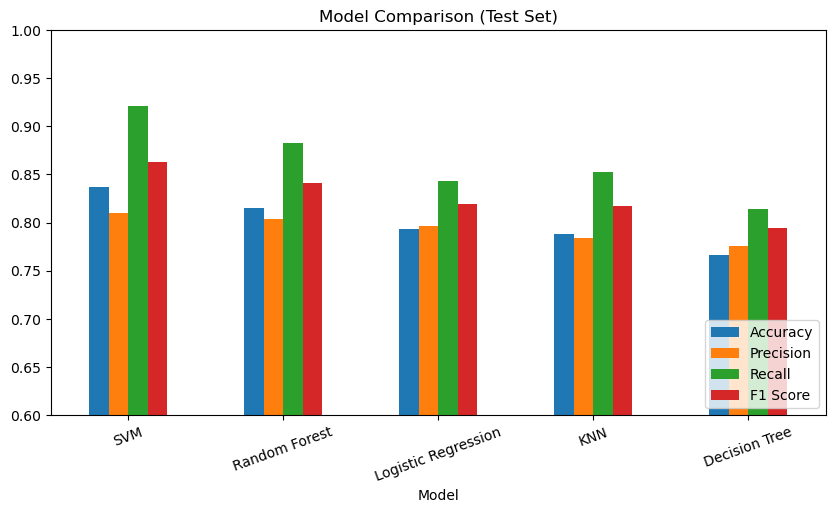

In [48]:
results_df.set_index('Model')[['Accuracy', 'Precision', 'Recall', 'F1 Score']].plot(
    kind='bar', figsize=(10, 5), ylim=(0.6, 1)
)
plt.title('Model Comparison (Test Set)')
plt.xticks(rotation=20)
plt.legend(loc='lower right')
plt.show()

<div dir="rtl" style="text-align: right;">
<h3>هل تفوق SVM حقيقي أم محظوظ في هذا التقسيم؟</h3>
<p>نكرر التجربة 5 مرات على أجزاء مختلفة من بيانات التدريب فقط، ونأخذ المتوسط ومقدار التذبذب. (والتجهيز يُعاد حسابه داخل كل مرة حتى لا يتسرب شيء.)</p>
<p><b>النتيجة (مقياس F1):</b> SVM 0.841، ثم Random Forest 0.827، وKNN 0.825، وLogistic Regression 0.817، وأخيرًا الشجرة 0.749.</p>
<p><b>المعنى:</b> SVM يتصدر أيضًا في هذا الاختبار الأصلب، لكن تفوقه على الثلاثة التالين (نحو 0.014 إلى 0.023) قريب من حجم التذبذب نفسه (نحو 0.02)، فهو <b>تفوق طفيف وليس حاسمًا</b>. أما الشجرة الواحدة فهي الأضعف بوضوح.</p>
</div>

In [49]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

candidates = {
    'Logistic Regression': LogisticRegression(max_iter=2000, random_state=42),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=200, random_state=42),
    'KNN': KNeighborsClassifier(n_neighbors=5),
    'SVM': SVC(kernel='rbf', probability=True, random_state=42),
}

cv_rows = []
for name, clf in candidates.items():
    pipe = Pipeline([('prep', preprocessor), ('clf', clf)])
    scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring='f1')
    cv_rows.append({'Model': name, 'CV F1 mean': scores.mean(), 'CV F1 std': scores.std()})

pd.DataFrame(cv_rows).sort_values('CV F1 mean', ascending=False)

,Model,CV F1 mean,CV F1 std
4,SVM,0.840707,0.023176
2,Random Forest,0.826889,0.025193
3,KNN,0.825270,0.024798
0,Logistic Regression,0.817449,0.015723
1,Decision Tree,0.749231,0.043921


<div dir="rtl" style="text-align: right;">
<h3>هل يمكن تحسين النماذج بتغيير إعداداتها؟</h3>
<p>نجرب عدة إعدادات للنماذج الثلاثة الأفضل، ونختار الأحسن بالتحقق المتقاطع على بيانات التدريب فقط (دون لمس الاختبار).</p>
<p><b>النتيجة:</b> لا تحسن جوهري. SVM اختار إعداداته الافتراضية نفسها فلم يتغير أداؤه، وRandom Forest تحسن قليلًا في التحقق المتقاطع (من 0.827 إلى 0.831) دون أن يتفوق في الاختبار (F1 = 0.815). <b>الدرس:</b> الإعدادات الافتراضية كانت قريبة من الأفضل، ويرجّح هذا أن تحسين الأداء يحتاج بيانات أكثر أو أفضل لا مجرد ضبط الإعدادات.</p>
</div>

In [50]:
from sklearn.model_selection import GridSearchCV

grids = {
    'Logistic Regression': (LogisticRegression(max_iter=2000, random_state=42),
                            {'clf__C': [0.1, 1, 10]}),
    'Random Forest': (RandomForestClassifier(random_state=42),
                      {'clf__n_estimators': [200, 400], 'clf__max_depth': [None, 5, 10], 'clf__min_samples_leaf': [1, 3]}),
    'SVM': (SVC(kernel='rbf', probability=True, random_state=42),
            {'clf__C': [0.5, 1, 5], 'clf__gamma': ['scale', 0.05]}),
}

tuned = {}
tuned_rows = []
for name, (clf, grid) in grids.items():
    pipe = Pipeline([('prep', preprocessor), ('clf', clf)])
    search = GridSearchCV(pipe, grid, scoring='f1', cv=cv, n_jobs=-1)
    search.fit(X_train, y_train)
    tuned[name] = search.best_estimator_
    tuned_rows.append({
        'Model': name,
        'Best CV F1': search.best_score_,
        'Test F1': f1_score(y_test, search.predict(X_test)),
        'Test Recall': recall_score(y_test, search.predict(X_test)),
        'Best params': search.best_params_,
    })

pd.DataFrame(tuned_rows).sort_values('Best CV F1', ascending=False)

,Model,Best CV F1,Test F1,Test Recall,Best params
2,SVM,0.840707,0.862385,0.921569,"{'clf__C': 1, 'clf__gamma': 'scale'}"
1,Random Forest,0.830732,0.815166,0.843137,"{'clf__max_depth': None, 'clf__min_samples_lea..."
0,Logistic Regression,0.820854,0.819048,0.843137,{'clf__C': 0.1}


<div dir="rtl" style="text-align: right;">
<h3>القرار: اعتماد SVM نموذجًا نهائيًا</h3>
<p>اخترناه بنتيجة التحقق المتقاطع (0.841، الأعلى) وليس بنتيجة الاختبار. وهذا أداؤه على 184 مريضًا لم يؤثروا في أي قرار:</p>
<ul>
<li><b>يكتشف 92% من المصابين</b> (94 من 102)، ويفوته نحو مريض من كل 13 مصابًا.</li>
<li><b>دقة 84%</b>، ومن كل 100 إنذار بالإصابة نحو 81 صحيحة (Precision = 0.81).</li>
<li><b>ROC-AUC = 0.889:</b> مقياس لقدرة النموذج على التمييز بين المصاب والسليم (0.5 يعني تخمينًا عشوائيًا و1.0 يعني تمييزًا مثاليًا). الرقم جيد وليس ممتازًا.</li>
</ul>
<p>الرسمان: مصفوفة الأخطاء (يسار) ومنحنى ROC (يمين).</p>
</div>

Best model: SVM
              precision    recall  f1-score   support

           0       0.88      0.73      0.80        82
           1       0.81      0.92      0.86       102

    accuracy                           0.84       184
   macro avg       0.85      0.83      0.83       184
weighted avg       0.84      0.84      0.83       184



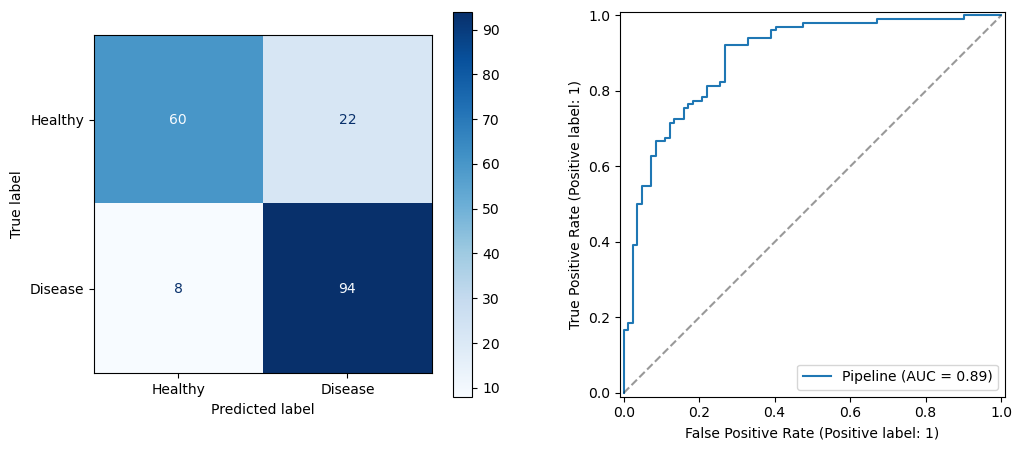

ROC-AUC: 0.8885700621712099


In [51]:
best_name = max(tuned_rows, key=lambda r: r['Best CV F1'])['Model']
best_model = tuned[best_name]
print('Best model:', best_name)

best_pred = best_model.predict(X_test)
print(classification_report(y_test, best_pred))

from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay, roc_auc_score
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay.from_estimator(best_model, X_test, y_test, cmap='Blues', ax=axes[0],
                                      display_labels=['Healthy', 'Disease'])
RocCurveDisplay.from_estimator(best_model, X_test, y_test, ax=axes[1])
axes[1].plot([0, 1], [0, 1], 'k--', alpha=0.4)
plt.show()
print('ROC-AUC:', roc_auc_score(y_test, best_model.predict_proba(X_test)[:, 1]))

<div dir="rtl" style="text-align: right;">
<h3>على ماذا يعتمد النموذج في قراره؟</h3>
<p>الطبيب لن يثق في نظام لا يفهم سبب قراره. لذلك نخلط قيم معلومة واحدة عشوائيًا ونقيس مقدار تراجع الأداء: كلما تراجع أكثر، كانت المعلومة أهم.</p>
<p><b>النتيجة:</b> نوع ألم الصدر (cp) هو الأهم بفارق كبير (0.082)، ثم oldpeak (0.038). وهذا يتفق في الاتجاه العام مع ما رأيناه في الرسوم ومع المنطق الطبي. أما fbs وslope وrestecg فتأثيرها شبه معدوم.</p>
<p><b>تنبيه:</b> ترتيب المعلومات بعد الأولى تقريبي لأن الاختبار صغير. فمثلًا ضغط الدم يظهر ثالثًا (0.035) رغم ضعف ارتباطه في الرسم، والأرجح أنه ضجيج عينة صغيرة وليس أهمية طبية حقيقية.</p>
</div>

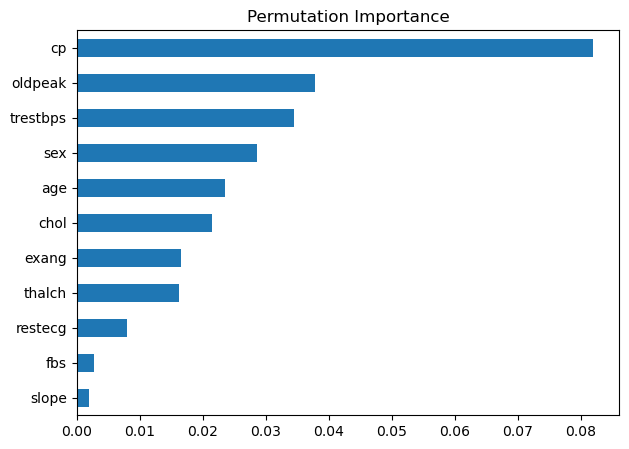

In [52]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(best_model, X_test, y_test, scoring='f1', n_repeats=20, random_state=42)
importance = pd.Series(perm.importances_mean, index=X_test.columns).sort_values()
importance.plot(kind='barh', figsize=(7, 5), title='Permutation Importance')
plt.show()

<div dir="rtl" style="text-align: right;">
<h2>من النموذج إلى أداة يستخدمها الطبيب والممرض</h2>
<p>النموذج وحده لا يفيد أحدًا في العيادة؛ نحتاج وسيلة يدخل بها الطبيب أو الممرض بيانات المريض ويستلم النتيجة فورًا. نبنيها على ثلاث خطوات: <b>حفظ النموذج</b>، ثم <b>تجربته على مريض جديد</b>، ثم <b>تقديمه عبر واجهة برمجية (API)</b> يمكن لأي نظام أو تطبيق في المستشفى أن يتصل بها.</p>
</div>

<div dir="rtl" style="text-align: right;">
<h3>الخطوة 1: حفظ النموذج</h3>
<p>نحفظ النموذج النهائي <b>مع خطوات تجهيز البيانات</b> في ملف واحد. الفائدة العملية: عند تشغيل النظام لا نعيد التدريب (فهو يستغرق وقتًا وقد تتغير نتائجه)، وتُعالَج بيانات أي مريض جديد بالقواعد نفسها التي تعلّم بها النموذج.</p>
</div>

In [53]:

import joblib
from pathlib import Path

MODEL_PATH = Path("../models/heart_disease_pipeline.pkl")
MODEL_PATH.parent.mkdir(exist_ok=True)

joblib.dump(best_model, MODEL_PATH)
print("Model saved:", MODEL_PATH)

Model saved: ..\models\heart_disease_pipeline.pkl


<div dir="rtl" style="text-align: right;">
<h3>الخطوة 2: تجربة النموذج المحفوظ على مريض جديد</h3>
<p>نحمّل الملف كما سيفعل النظام الحقيقي، ونعطيه بيانات مريض بالشكل الذي يدخله الطبيب. هذا اختبار قبول بسيط: إذا أعطى نتيجة منطقية لمريض نعرف أنه عالي الخطورة (رجل 55 سنة بلا ألم صدر نموذجي، ونبضه أثناء المجهود 120 وفيه ألم صدر عند المجهود) فالنموذج المحفوظ سليم.</p>
</div>

In [54]:

loaded_model = joblib.load(MODEL_PATH)

new_patient = pd.DataFrame([{
    "age": 55, "sex": "Male", "cp": "asymptomatic",
    "trestbps": 140, "chol": 250, "fbs": False, "restecg": "normal",
    "thalch": 120, "exang": True, "oldpeak": 2.0, "slope": "flat",
}], dtype=object)   # object: نفس نوع أعمدة fbs و exang أثناء التدريب

probability = loaded_model.predict_proba(new_patient)[0, 1]
print(f"Probability of heart disease: {probability:.1%}")
print("Result:", "Heart disease detected" if probability >= 0.5 else "No heart disease detected")

Probability of heart disease: 95.7%
Result: Heart disease detected


<div dir="rtl" style="text-align: right;">
<h3>الخطوة 3: الواجهة البرمجية (API)</h3>
<p>الواجهة هي «شباك الاستقبال» للنموذج: يرسل لها الطبيب بيانات المريض، فترد بالتشخيص المبدئي. القرارات المهمة في تصميمها:</p>
<ul>
<li><b>الحد الأدنى من البيانات:</b> ثلاث معلومات فقط مطلوبة (العمر والجنس ونوع ألم الصدر). الباقي اختياري، وما لم يُدخَل يعوّضه النموذج بنفس قواعد التدريب. هكذا لا تتعطل الخدمة أمام ممرض لم تصله نتيجة فحص بعد.</li>
<li><b>رفض البيانات الخاطئة:</b> لو كتب أحدهم عمرًا مستحيلًا (500) أو قيمة غير معروفة، ترفض الواجهة الطلب برسالة واضحة بدل أن تعطي نتيجة مضللة.</li>
<li><b>تنبيه مبكر:</b> إذا تجاوز احتمال الإصابة <b>80%</b> يظهر <code>early_alert: true</code> لينتبه الطبيب. هذا الرقم قرار إداري، وليس حقيقة علمية، ويمكن تغييره حسب سياسة المستشفى (متغير <code>ALERT_THRESHOLD</code>).</li>
<li><b>تنبيه قانوني:</b> كل رد يحمل عبارة أن النتيجة تنبؤ مبدئي وليست تشخيصًا طبيًا.</li>
</ul>
<p>الخلية التالية تكتب الواجهة في ملف <code>api.py</code> بمجلد المشروع (أمر <code dir="ltr">%%writefile</code>)، فهو ملف التشغيل الفعلي.</p>
</div>

In [55]:
%%writefile ../api.py
"""Flask API: توقع مبدئي لمرض القلب.

التشغيل:  python api.py   (بعد تدريب النموذج: python -m src.train)
"""
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
from flask import Flask, jsonify, request

MODEL_PATH = Path(__file__).resolve().parent / "models" / "heart_disease_pipeline.pkl"
ALERT_THRESHOLD = 0.80   # احتمال الإصابة فوق هذا الرقم يطلق تنبيهًا مبكرًا للطبيب
DISCLAIMER = "تنبؤ مبدئي لأغراض تعليمية، وليس تشخيصًا طبيًا."

NUMERIC = {            # الحد الأدنى والأقصى المنطقي لكل قياس
    "age": (1, 120),
    "trestbps": (50, 260),
    "chol": (50, 700),
    "thalch": (40, 250),
    "oldpeak": (-5, 10),
}
CATEGORICAL = {        # القيم المسموحة لكل معلومة وصفية
    "sex": ["Male", "Female"],
    "cp": ["typical angina", "atypical angina", "non-anginal", "asymptomatic"],
    "restecg": ["normal", "st-t abnormality", "lv hypertrophy"],
    "slope": ["upsloping", "flat", "downsloping"],
}
BOOLEAN = ["fbs", "exang"]
REQUIRED = ["age", "sex", "cp"]    # الباقي اختياري، والنموذج يعوض الناقص

app = Flask(__name__)
app.json.ensure_ascii = False
app.json.sort_keys = False         # يحافظ على ترتيب الحقول في الرد
model = joblib.load(MODEL_PATH)    # يُحمَّل مرة واحدة، ولا يوجد تدريب هنا


def check_input(data):
    """يرجع قائمة بالأخطاء (فارغة لو البيانات سليمة)."""
    errors = []
    if not isinstance(data, dict):
        return ["يجب إرسال بيانات المريض بصيغة JSON object"]

    for name in REQUIRED:
        if data.get(name) is None:
            errors.append(f"الحقل '{name}' مطلوب")

    for name, (low, high) in NUMERIC.items():
        value = data.get(name)
        if value is None:
            continue
        if isinstance(value, bool) or not isinstance(value, (int, float)):
            errors.append(f"'{name}' يجب أن يكون رقمًا")
        elif not low <= value <= high:
            errors.append(f"'{name}' يجب أن يكون بين {low} و{high}")

    for name, allowed in CATEGORICAL.items():
        value = data.get(name)
        if value is not None and value not in allowed:
            errors.append(f"'{name}' يجب أن يكون واحدًا من {allowed}")

    for name in BOOLEAN:
        value = data.get(name)
        if value is not None and not isinstance(value, bool):
            errors.append(f"'{name}' يجب أن يكون true أو false")

    return errors


def to_dataframe(data):
    """يحوّل بيانات المريض إلى صف واحد بنفس شكل بيانات التدريب."""
    row = {}
    for name in list(NUMERIC) + list(CATEGORICAL) + BOOLEAN:
        value = data.get(name)
        # القيمة غير المرسلة تصبح NaN (وليس None) حتى يعوضها النموذج مثل بيانات التدريب
        row[name] = np.nan if value is None else value
    return pd.DataFrame([row], dtype=object)   # object مثل أعمدة fbs/exang في النوتبوك


@app.get("/health")
def health():
    return jsonify({"status": "ok"})


@app.post("/predict")
def predict():
    data = request.get_json(silent=True)
    errors = check_input(data)
    if errors:
        return jsonify({"errors": errors}), 400

    probability = float(model.predict_proba(to_dataframe(data))[0, 1])
    sick = probability >= 0.5

    return jsonify({
        "prediction": int(sick),
        "result": "Heart disease detected" if sick else "No heart disease detected",
        "probability": round(probability, 3),
        "early_alert": probability >= ALERT_THRESHOLD,
        "disclaimer": DISCLAIMER,
    })


if __name__ == "__main__":
    app.run(debug=False)

Overwriting ../api.py


<div dir="rtl" style="text-align: right;">
<h3>الخطوة 4: اختبار الواجهة قبل تسليمها</h3>
<p>نجرب الواجهة بأربع حالات تمثل ما سيحدث في الاستخدام الفعلي، دون تشغيل خادم: مريض عالي الخطورة، ومريض منخفض الخطورة، ومريض بيانات ناقصة، ومريض ببيانات خاطئة. المطلوب: رد <b>200</b> مع نتيجة منطقية للحالات الثلاث الأولى، وفي الحالة الرابعة رد <b>400</b> مع رسالة توضح الخطأ.</p>
</div>

In [56]:

import sys
sys.path.append("..")            # لنستورد api.py من مجلد المشروع
from api import app

client = app.test_client()

def ask(title, patient):
    response = client.post("/predict", json=patient)
    print(f"--- {title}  [HTTP {response.status_code}]")
    print(response.get_json(), "\n")

ask("High-risk patient", {
    "age": 55, "sex": "Male", "cp": "asymptomatic", "trestbps": 140, "chol": 250,
    "fbs": False, "restecg": "normal", "thalch": 120, "exang": True,
    "oldpeak": 2.0, "slope": "flat"})

ask("Low-risk patient", {
    "age": 35, "sex": "Female", "cp": "atypical angina", "trestbps": 115, "chol": 190,
    "fbs": False, "restecg": "normal", "thalch": 175, "exang": False,
    "oldpeak": 0.0, "slope": "upsloping"})

ask("Only the 3 required fields", {"age": 55, "sex": "Male", "cp": "asymptomatic"})

ask("Invalid data", {"age": 500, "sex": "M", "cp": "asymptomatic", "chol": "high"})

--- High-risk patient  [HTTP 200]
{'prediction': 1, 'result': 'Heart disease detected', 'probability': 0.957, 'early_alert': True, 'disclaimer': 'تنبؤ مبدئي لأغراض تعليمية، وليس تشخيصًا طبيًا.'} 

--- Low-risk patient  [HTTP 200]
{'prediction': 0, 'result': 'No heart disease detected', 'probability': 0.046, 'early_alert': False, 'disclaimer': 'تنبؤ مبدئي لأغراض تعليمية، وليس تشخيصًا طبيًا.'} 

--- Only the 3 required fields  [HTTP 200]
{'prediction': 1, 'result': 'Heart disease detected', 'probability': 0.79, 'early_alert': False, 'disclaimer': 'تنبؤ مبدئي لأغراض تعليمية، وليس تشخيصًا طبيًا.'} 

--- Invalid data  [HTTP 400]
{'errors': ["'age' يجب أن يكون بين 1 و120", "'chol' يجب أن يكون رقمًا", "'sex' يجب أن يكون واحدًا من ['Male', 'Female']"]} 



--- Low-risk patient  [HTTP 200]
{'prediction': 0, 'result': 'No heart disease detected', 'probability': 0.046, 'early_alert': False, 'disclaimer': 'تنبؤ مبدئي لأغراض تعليمية، وليس تشخيصًا طبيًا.'} 



--- Only the 3 required fields  [HTTP 200]
{'prediction': 1, 'result': 'Heart disease detected', 'probability': 0.79, 'early_alert': False, 'disclaimer': 'تنبؤ مبدئي لأغراض تعليمية، وليس تشخيصًا طبيًا.'} 

--- Invalid data  [HTTP 400]
{'errors': ["'age' يجب أن يكون بين 1 و120", "'chol' يجب أن يكون رقمًا", "'sex' يجب أن يكون واحدًا من ['Male', 'Female']"]} 



<div dir="rtl" style="text-align: right;">
<h3>تشغيل الخدمة فعليًا</h3>
<p>نشغّل الخادم من خارج النوتبوك (لأنه يبقى يعمل ويوقف بقية الخلايا). من مجلد المشروع في الـ Terminal:</p>
<pre dir="ltr" style="text-align: left;">python api.py</pre>
<p>تصبح الخدمة على العنوان <code>http://127.0.0.1:5000</code>، والمسارات المتاحة:</p>
<ul>
<li><code>GET /health</code>: للتأكد أن الخدمة تعمل.</li>
<li><code>POST /predict</code>: لإرسال بيانات مريض واستلام التشخيص المبدئي.</li>
</ul>
<p>مثال لإرسال طلب (بعد تشغيل الخادم) بلغة Python:</p>
<pre dir="ltr" style="text-align: left;">import requests

patient = {"age": 55, "sex": "Male", "cp": "asymptomatic"}
print(requests.post("http://127.0.0.1:5000/predict", json=patient).json())</pre>
<p>وللأطباء واجهة ويب مرئية في الملف <code>app.py</code>، تُشغَّل بالأمر <code dir="ltr">streamlit run app.py</code> وتعرض النتيجة والتنبيه المبكر وأقرب 3 مرضى مشابهين.</p>
</div>

<div dir="rtl" style="text-align: right;">
<h2>الخلاصة والتوصية</h2>
<p><b>ما أنجزناه:</b> نظام يقدّر احتمال إصابة مريض بمرض القلب من 11 معلومة بسيطة. أفضل نموذج هو <b>SVM</b>: يكتشف 92% من المصابين ويصيب في 84% من الحالات على مرضى لم يرهم من قبل.</p>
<p><b>التوصية:</b> اعتماده <b>نموذجًا أوليًا لمرحلة تجريبية تحت إشراف طبي</b> (أداة مساندة للفرز)، وليس للاستخدام السريري المستقل، للأسباب التالية:</p>
<ul>
<li><b>حجم البيانات صغير:</b> 920 مريضًا فقط، ولذلك تحتمل الأرقام هامش خطأ كبيرًا.</li>
<li><b>التمثيل غير متوازن:</b> نحو 79% من المرضى رجال (726 رجلًا مقابل 194 امرأة)، فأداء النموذج على النساء غير مضمون.</li>
<li><b>جودة التسجيل متفاوتة:</b> المرضى من أربع مستشفيات، و22% من قيم الكوليسترول غير مسجلة، ولم نختبر النموذج على مستشفى خارج هذه المستشفيات.</li>
<li><b>الأخطاء واردة:</b> يفوّت نحو 8% من المصابين، ولا يوجد نموذج يعمل بدقة 100%.</li>
</ul>
</div>